# Airbnb Madrid — Análisis Exploratorio: hallazgos para el dashboard

Continuación de `01_exploracion_limpieza.ipynb`. Aquí buscamos las **relaciones y patrones
más interesantes** del dataset, con el objetivo de decidir qué merece un lugar en el dashboard.

Cada sección plantea una pregunta, la responde con datos y cierra con la **implicación para
el dashboard**. Al final hay una tabla resumen hallazgo → visualización propuesta.

Preguntas que exploramos:

1. ¿Qué variables determinan el precio de un anuncio?
2. ¿Cuánto pesan la capacidad y el tipo de alojamiento?
3. ¿Cuánto vale la ubicación? (distritos y distancia al centro)
4. ¿Se paga la calidad? (ratings vs precio — con sorpresa)
5. ¿Quién opera los anuncios? La profesionalización del mercado
6. El efecto Superhost
7. ¿Cómo ha evolucionado la demanda? (2011–2025, con COVID)
8. Estacionalidad: la temporada alta de octubre y la caída de agosto
9. Ocupación futura según el calendario
10. Licencias turísticas: ¿dónde se cumple la norma?

## 0. Setup: datos y estilo de gráficos

Definimos una paleta única para todo el notebook (y reutilizable en el dashboard):
un azul como color principal de magnitud, una rampa secuencial de un solo tono para
mapas de intensidad, y el par azul/rojo sólo para polaridad (correlaciones + / −).
Reglas que seguimos en todos los gráficos: un solo eje Y (nunca ejes duales), barras
con etiquetas directas, rejilla discreta detrás de los datos, y color por significado
(no decorativo).

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# --- paleta (validada para daltonismo; misma que usará el dashboard) ---
INK, INK2, MUTED = '#0b0b0b', '#52514e', '#898781'
GRID, BASE, SURFACE = '#e1e0d9', '#c3c2b7', '#fcfcfb'
BLUE, BLUE_L, BLUE_D = '#2a78d6', '#9ec5f4', '#104281'
RED, AQUA = '#e34948', '#1baf7a'
SEQ = ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b']
CMAP_SEQ = LinearSegmentedColormap.from_list('azul_seq', SEQ)

mpl.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': BASE, 'axes.linewidth': 1,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.spines.left': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK2,
    'axes.labelcolor': INK2, 'axes.titlecolor': INK, 'axes.titleweight': 'bold',
    'axes.titlesize': 12, 'axes.titlelocation': 'left', 'axes.titlepad': 12,
    'font.size': 10, 'figure.dpi': 110, 'legend.frameon': False,
})

def estilo(ax, eje='y'):
    """Rejilla sólo en el eje de lectura, sin ticks marcados."""
    ax.grid(axis=eje)
    ax.grid(axis='x' if eje == 'y' else 'y', visible=False)
    ax.tick_params(length=0)

In [2]:
P = '../data/processed'
listings = pd.read_parquet(f'{P}/listings.parquet')
full = pd.read_parquet(f'{P}/listings_full.parquet')
reviews = pd.read_parquet(f'{P}/reviews.parquet')
cal = pd.read_parquet(f'{P}/calendar.parquet', columns=['listing_id', 'date', 'available'])

# Base para análisis de PRECIO: sólo anuncios con precio conocido y recortando el 1%
# superior (outliers de 1.000-37.000 EUR/noche que distorsionan medias y escalas).
d = full[full.price.notna() & (full.price < full.price.quantile(0.99))].copy()
d['log_price'] = np.log10(d['price'])

# Distancia al km 0 (Puerta del Sol) en km, aproximación plana válida a escala de ciudad
SOL_LAT, SOL_LON = 40.41678, -3.70379
d['dist_km'] = np.sqrt(((d.latitude - SOL_LAT) * 111.32) ** 2
                       + ((d.longitude - SOL_LON) * 111.32 * np.cos(np.radians(SOL_LAT))) ** 2)

print(f'anuncios totales:            {len(full):,}')
print(f'base de análisis de precio:  {len(d):,}  (con precio, sin el 1% superior)')
print(f'reseñas:                     {len(reviews):,}')
print(f'filas de calendario:         {len(cal):,}')

anuncios totales:            22,708
base de análisis de precio:  18,980  (con precio, sin el 1% superior)
reseñas:                     1,419,360
filas de calendario:         8,334,782


> **Nota sobre las reseñas duplicadas:** en el notebook 01 vimos 11.070 filas repetidas en
> `reviews` (resumen). Verificado contra `reviews_full` (mismo nº de filas, 0 ids de reseña
> duplicados): son reseñas **distintas** que coinciden en anuncio y fecha — dos huéspedes
> reseñando el mismo día. **No se deduplica**; hacerlo infracontaría la demanda.

## 1. ¿Qué determina el precio?

Correlacionamos el **log del precio** (el precio es log-normal: usar el log evita que los
pisos caros dominen la correlación) con las variables numéricas del anuncio.

In [3]:
vars_precio = {
    'accommodates': 'Capacidad (huéspedes)',
    'bedrooms': 'Dormitorios',
    'beds': 'Camas',
    'bathrooms': 'Baños',
    'review_scores_location': 'Rating: ubicación',
    'review_scores_cleanliness': 'Rating: limpieza',
    'review_scores_rating': 'Rating global',
    'number_of_reviews': 'Nº de reseñas',
    'availability_365': 'Disponibilidad anual',
    'calculated_host_listings_count': 'Anuncios del host',
    'dist_km': 'Distancia al centro (km)',
    'minimum_nights': 'Noches mínimas',
}
corr = (d[list(vars_precio) + ['log_price']].corr(numeric_only=True)['log_price']
        .drop('log_price').rename(vars_precio).sort_values())
corr.round(3)

Noches mínimas             -0.327
Distancia al centro (km)   -0.216
Anuncios del host           0.034
Disponibilidad anual        0.041
Nº de reseñas               0.071
Rating global               0.091
Rating: limpieza            0.129
Rating: ubicación           0.143
Baños                       0.207
Camas                       0.269
Dormitorios                 0.377
Capacidad (huéspedes)       0.604
Name: log_price, dtype: float64

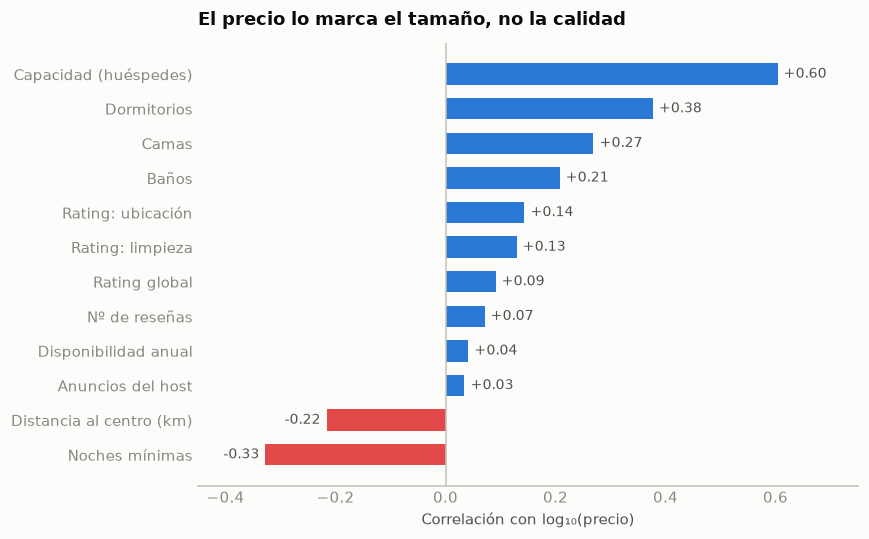

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
colores = [BLUE if v > 0 else RED for v in corr]
bars = ax.barh(corr.index, corr.values, color=colores, height=0.62)
ax.bar_label(bars, fmt='%+.2f', padding=4, fontsize=9, color=INK2)
ax.axvline(0, color=BASE, lw=1)
ax.set_xlim(-0.45, 0.75)
ax.set_title('El precio lo marca el tamaño, no la calidad')
ax.set_xlabel('Correlación con log₁₀(precio)')
estilo(ax, eje='x')
plt.tight_layout()
plt.show()

**Hallazgo:** el precio es sobre todo una función de **capacidad** (r ≈ 0,60 con huéspedes,
0,38 con dormitorios). Los ratings apenas correlacionan (rating global r ≈ 0,09): pagar más
no compra una experiencia mejor valorada. Las dos correlaciones negativas tienen lógica
propia: más **noches mínimas** = alquiler de temporada, más barato por noche; y más
**distancia al centro** = menos premium de ubicación (lo cuantificamos en la sección 3).

**Para el dashboard:** este gráfico funciona como "portada analítica" — desmonta la
intuición de que caro = mejor valorado.

## 2. Capacidad y tipo de alojamiento

Si la capacidad manda, la relación precio–huéspedes debería ser casi lineal, y el tipo de
alojamiento debería ordenar los precios de forma limpia.

In [5]:
por_tipo = (d.groupby('room_type', observed=True)['price']
            .agg(['median', 'count']).sort_values('median', ascending=False))
por_cap = (d[d.accommodates.between(1, 8)]
           .groupby('accommodates')['price'].agg(['median', 'count']))
print(por_tipo)
por_cap

                 median  count
room_type                     
Entire home/apt  143.33  13798
Hotel room       104.00     29
Private room      64.00   5012
Shared room       25.00    141


,median,count
accommodates,,
1,44.000,2226
2,100.080,6496
3,124.300,1896
4,147.060,4996
5,175.000,826
6,212.155,1648
7,226.585,208
8,290.000,403


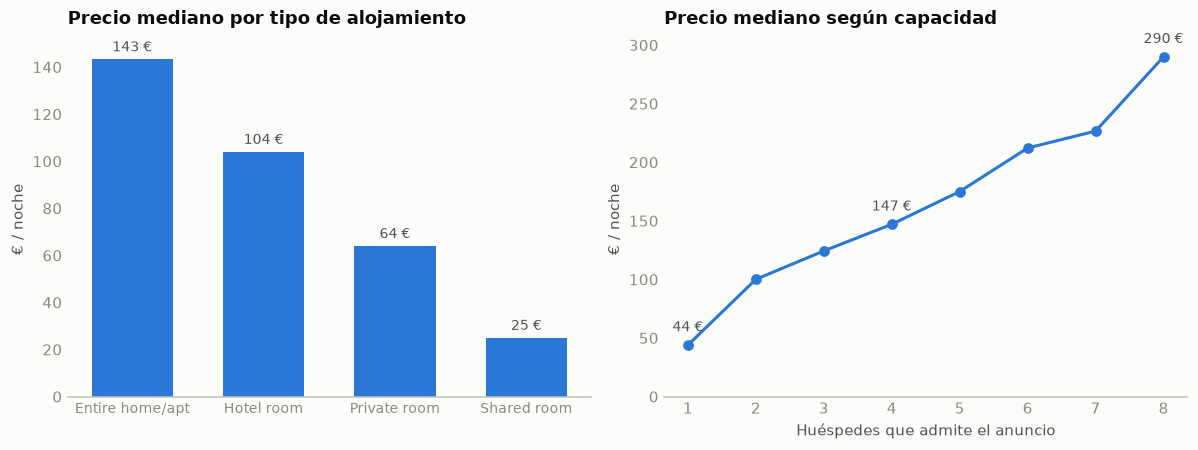

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

bars = ax1.bar(por_tipo.index.astype(str), por_tipo['median'], color=BLUE, width=0.62)
ax1.bar_label(bars, fmt='%.0f €', padding=3, fontsize=9, color=INK2)
ax1.set_title('Precio mediano por tipo de alojamiento')
ax1.set_ylabel('€ / noche')
ax1.tick_params(axis='x', labelsize=9)
estilo(ax1)

ax2.plot(por_cap.index, por_cap['median'], color=BLUE, lw=2, marker='o', ms=6)
for x, y in por_cap['median'].items():
    if x in (1, 4, 8):
        ax2.annotate(f'{y:.0f} €', (x, y), textcoords='offset points',
                     xytext=(0, 9), ha='center', fontsize=9, color=INK2)
ax2.set_title('Precio mediano según capacidad')
ax2.set_xlabel('Huéspedes que admite el anuncio')
ax2.set_ylabel('€ / noche')
ax2.set_ylim(0, None)
estilo(ax2)
plt.tight_layout()
plt.show()

**Hallazgo:** la jerarquía es limpia y enorme: piso entero **~143 €** vs habitación privada
**~64 €** vs compartida **~25 €** — y el precio mediano escala casi linealmente con cada
huésped adicional. El 73% de la oferta con precio son pisos enteros.

**Para el dashboard:** el tipo de alojamiento es el **filtro global** más importante;
mezclar tipos en una media de precios la deja sin sentido.

## 3. ¿Cuánto vale la ubicación?

Tres vistas del mismo fenómeno: precio mediano por distrito, el "mapa" de puntos coloreado
por precio, y el gradiente de precio según la distancia a la Puerta del Sol.

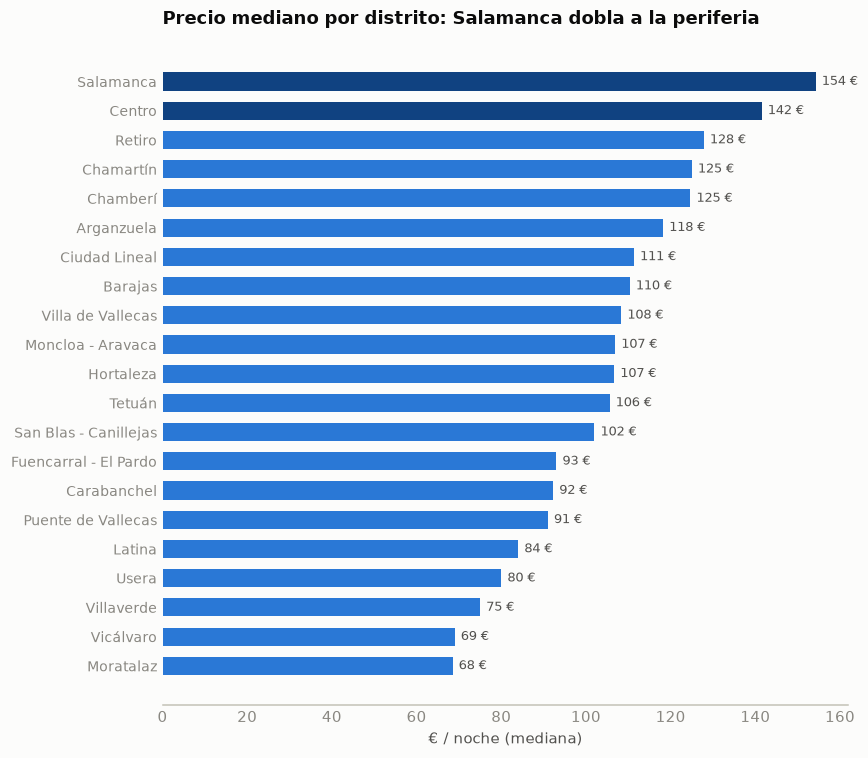

In [7]:
por_distrito = (d.groupby('neighbourhood_group_cleansed', observed=True)['price']
                .agg(['median', 'count']).sort_values('median'))

fig, ax = plt.subplots(figsize=(8, 7))
colores = [BLUE_D if dist in ('Salamanca', 'Centro') else BLUE for dist in por_distrito.index]
bars = ax.barh(por_distrito.index.astype(str), por_distrito['median'], color=colores, height=0.62)
ax.bar_label(bars, fmt='%.0f €', padding=4, fontsize=8.5, color=INK2)
ax.set_title('Precio mediano por distrito: Salamanca dobla a la periferia')
ax.set_xlabel('€ / noche (mediana)')
ax.tick_params(axis='y', labelsize=9)
estilo(ax, eje='x')
plt.tight_layout()
plt.show()

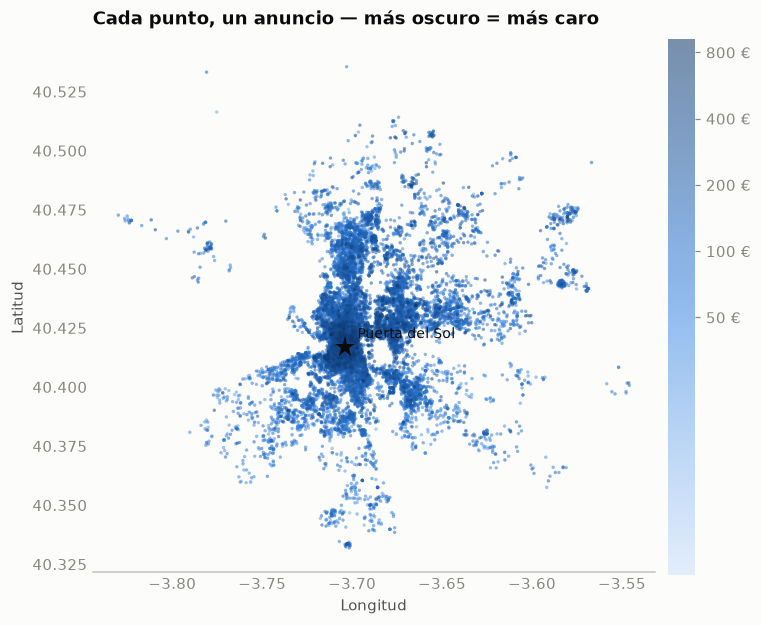

In [8]:
fig, ax = plt.subplots(figsize=(7.2, 6.8))
dd = d.sort_values('log_price')  # los caros se dibujan encima y no quedan tapados
sc = ax.scatter(dd.longitude, dd.latitude, c=dd.log_price, cmap=CMAP_SEQ,
                s=5, alpha=0.55, linewidths=0)
ax.set_aspect(1 / np.cos(np.radians(SOL_LAT)))
ax.plot(SOL_LON, SOL_LAT, marker='*', ms=14, color=INK, mew=0)
ax.annotate('Puerta del Sol', (SOL_LON, SOL_LAT), textcoords='offset points',
            xytext=(8, 6), fontsize=9, color=INK)
cb = fig.colorbar(sc, ax=ax, shrink=0.75, pad=0.02)
ticks = [50, 100, 200, 400, 800]
cb.set_ticks(np.log10(ticks)); cb.set_ticklabels([f'{t} €' for t in ticks])
cb.outline.set_visible(False)
ax.set_title('Cada punto, un anuncio — más oscuro = más caro')
ax.grid(visible=False); ax.tick_params(length=0)
ax.set_xlabel('Longitud'); ax.set_ylabel('Latitud')
plt.tight_layout()
plt.show()

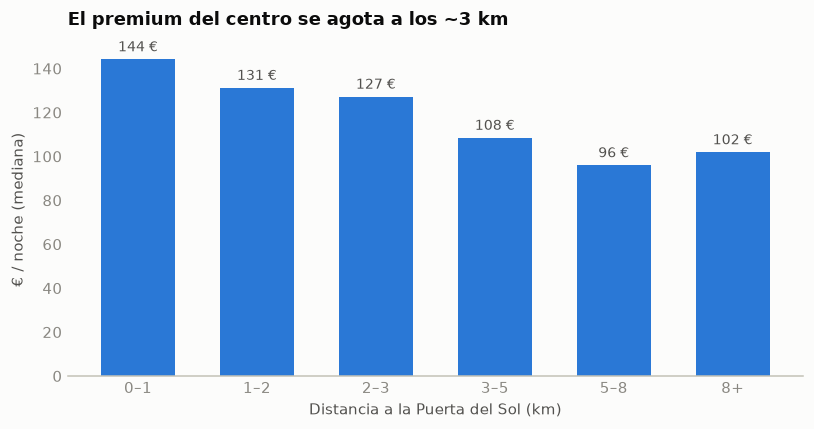

         median  count
dist_km               
0–1      144.25   6643
1–2      131.24   3111
2–3      127.23   2262
3–5      108.50   3823
5–8       96.00   2257
8+       101.92    884


In [9]:
anillos = pd.cut(d.dist_km, [0, 1, 2, 3, 5, 8, 15],
                 labels=['0–1', '1–2', '2–3', '3–5', '5–8', '8+'])
por_anillo = d.groupby(anillos, observed=True)['price'].agg(['median', 'count'])

fig, ax = plt.subplots(figsize=(7.5, 4))
bars = ax.bar(por_anillo.index.astype(str), por_anillo['median'], color=BLUE, width=0.62)
ax.bar_label(bars, fmt='%.0f €', padding=3, fontsize=9, color=INK2)
ax.set_title('El premium del centro se agota a los ~3 km')
ax.set_xlabel('Distancia a la Puerta del Sol (km)')
ax.set_ylabel('€ / noche (mediana)')
estilo(ax)
plt.tight_layout()
plt.show()
print(por_anillo)

**Hallazgo:** Salamanca (154 €) y Centro (142 €) más que doblan a Moratalaz o Vicálvaro
(~69 €). El gradiente por distancia es fuerte pero **se agota a los ~3 km** del km 0: a
partir de ahí el precio se aplana. Además, el rating de *ubicación* correlaciona con la
distancia (r ≈ −0,28): los huéspedes puntúan la ubicación tal y como el mapa predice.

**Para el dashboard:** ésta es la pieza central — un **mapa coroplético por barrio**
(tenemos el geojson) con selector de métrica (precio mediano, nº anuncios, % licencias).

## 4. ¿Se paga la calidad? Una sorpresa

Vimos que el rating apenas correlaciona con el precio. Miramos el detalle por cuartil de
precio, incluyendo la puntuación de **calidad-precio** (`review_scores_value`) — donde
cabría esperar que los pisos caros salieran castigados.

                review_scores_rating  review_scores_value
cuartil_precio                                           
Q1 (barato)                    4.596                4.507
Q2                             4.599                4.476
Q3                             4.647                4.526
Q4 (caro)                      4.699                4.594


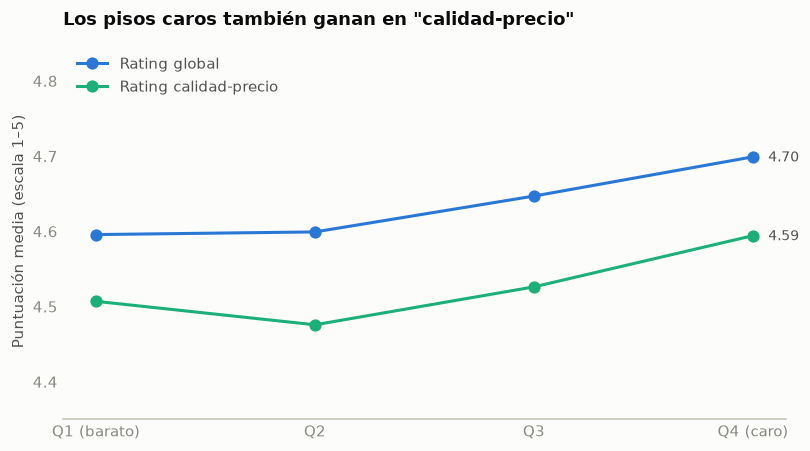

In [10]:
d['cuartil_precio'] = pd.qcut(d.price, 4, labels=['Q1 (barato)', 'Q2', 'Q3', 'Q4 (caro)'])
por_cuartil = (d.groupby('cuartil_precio', observed=True)
               [['review_scores_rating', 'review_scores_value']].mean())
print(por_cuartil.round(3))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
x = np.arange(len(por_cuartil))
ax.plot(x, por_cuartil.review_scores_rating, color=BLUE, lw=2, marker='o', ms=7,
        label='Rating global')
ax.plot(x, por_cuartil.review_scores_value, color=AQUA, lw=2, marker='o', ms=7,
        label='Rating calidad-precio')
for serie, col in [(por_cuartil.review_scores_rating, BLUE),
                   (por_cuartil.review_scores_value, AQUA)]:
    ax.annotate(f'{serie.iloc[-1]:.2f}', (x[-1], serie.iloc[-1]),
                textcoords='offset points', xytext=(10, -3), fontsize=9, color=INK2)
ax.set_xticks(x, por_cuartil.index.astype(str))
ax.set_ylim(4.35, 4.85)
ax.set_title('Los pisos caros también ganan en "calidad-precio"')
ax.set_ylabel('Puntuación media (escala 1–5)')
ax.legend(loc='upper left')
estilo(ax)
plt.tight_layout()
plt.show()

**Hallazgo (contraintuitivo):** no sólo el rating global sube con el precio — la puntuación
de **calidad-precio** también es *más alta* en el cuartil caro (4,59) que en el barato
(4,51). No existe el efecto "caro = clavada": los huéspedes del segmento alto se sienten
mejor tratados incluso ajustando por lo que pagan. Ojo: escala truncada (4,35–4,85) porque
las diferencias son de décimas — por eso usamos puntos/líneas y no barras.

**Para el dashboard:** buen candidato a "dato sorpresa" en una tarjeta destacada (KPI tile)
junto al scatter rating–precio con filtros.

## 5. ¿Quién opera los anuncios? La profesionalización del mercado

Agrupamos los anuncios según cuántos anuncios gestiona su host en Madrid
(`calculated_host_listings_count`): desde el particular con un piso hasta operadores
con cientos.

In [11]:
d['tipo_host'] = pd.cut(d.calculated_host_listings_count, [0, 1, 5, 20, 10_000],
                        labels=['1 anuncio', '2–5', '6–20', '21+'])
por_host = d.groupby('tipo_host', observed=True).agg(
    anuncios=('id', 'count'),
    disponibilidad_media=('availability_365', 'mean'),
    rating_medio=('review_scores_rating', 'mean'),
    precio_mediano=('price', 'median'),
).round(2)
print(por_host)
top = full.groupby('host_id').size().sort_values(ascending=False)
print(f'\nEl host más grande gestiona {top.iloc[0]:.0f} anuncios; '
      f'los 5 mayores suman {top.head(5).sum():.0f}.')

           anuncios  disponibilidad_media  rating_medio  precio_mediano
tipo_host                                                              
1 anuncio      4246                204.21          4.74          121.54
2–5            4603                210.24          4.70          118.50
6–20           4021                219.84          4.62          126.00
21+            6110                244.70          4.52          127.00

El host más grande gestiona 449 anuncios; los 5 mayores suman 1619.


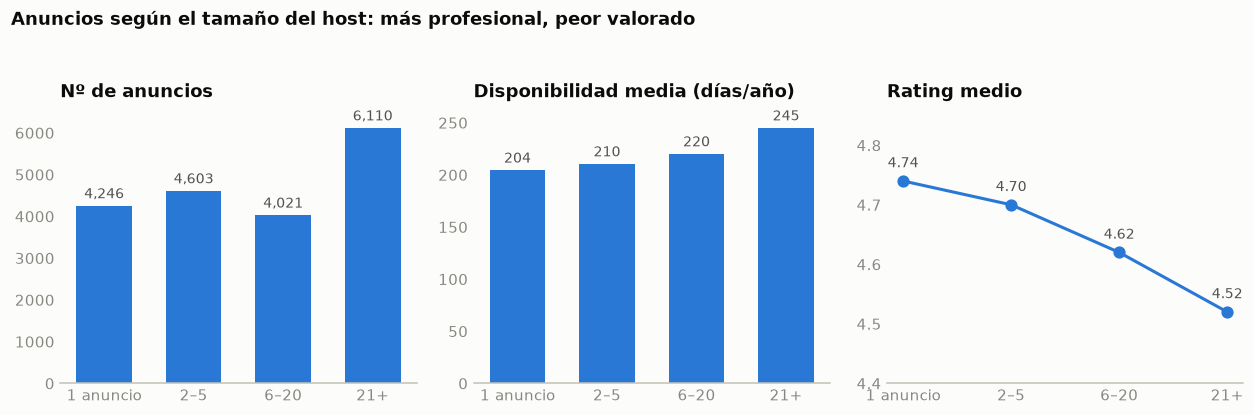

In [12]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(11.5, 3.8))

bars = ax1.bar(por_host.index.astype(str), por_host.anuncios, color=BLUE, width=0.62)
ax1.bar_label(bars, fmt='{:,.0f}', padding=3, fontsize=9, color=INK2)
ax1.set_title('Nº de anuncios')
estilo(ax1)

bars = ax2.bar(por_host.index.astype(str), por_host.disponibilidad_media, color=BLUE, width=0.62)
ax2.bar_label(bars, fmt='%.0f', padding=3, fontsize=9, color=INK2)
ax2.set_title('Disponibilidad media (días/año)')
estilo(ax2)

ax3.plot(por_host.index.astype(str), por_host.rating_medio, color=BLUE, lw=2, marker='o', ms=7)
for xx, yy in enumerate(por_host.rating_medio):
    ax3.annotate(f'{yy:.2f}', (xx, yy), textcoords='offset points', xytext=(0, 9),
                 ha='center', fontsize=9, color=INK2)
ax3.set_ylim(4.4, 4.85)
ax3.set_title('Rating medio')
estilo(ax3)

fig.suptitle('Anuncios según el tamaño del host: más profesional, peor valorado',
             x=0.01, ha='left', fontweight='bold', color=INK)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

**Hallazgo:** un **tercio de la oferta** (32%) está en manos de hosts con 21+ anuncios —
el mayor gestiona 449. Y hay un patrón claro: a más profesional el host, **más
disponibilidad** (245 vs 204 días/año: es negocio a tiempo completo, no el piso libre unas
semanas) y **peor rating** (4,52 vs 4,74 del particular). El trato personal se nota en las
reseñas.

**Para el dashboard:** segmentador "tipo de host" + este contraste como historia propia
("Airbnb ya no es de particulares").

## 6. El efecto Superhost

¿El distintivo de Superhost se traduce en actividad y precio?

                anuncios  rating_medio  reseñas_mes_mediana  precio_mediano
Resto de hosts     13866          4.55                 0.83          120.00
Superhost           5114          4.83                 2.18          132.63


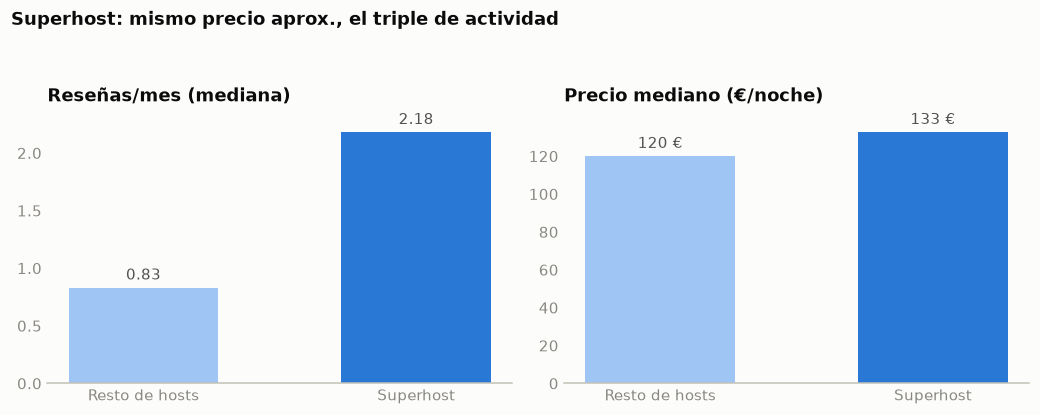

In [13]:
d['superhost'] = d.host_is_superhost == 't'
por_sh = d.groupby('superhost').agg(
    anuncios=('id', 'count'),
    rating_medio=('review_scores_rating', 'mean'),
    reseñas_mes_mediana=('reviews_per_month', 'median'),
    precio_mediano=('price', 'median'),
).round(2)
por_sh.index = ['Resto de hosts', 'Superhost']
print(por_sh)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 3.8))
for ax, colname, titulo, fmt in [
        (ax1, 'reseñas_mes_mediana', 'Reseñas/mes (mediana)', '%.2f'),
        (ax2, 'precio_mediano', 'Precio mediano (€/noche)', '%.0f €')]:
    bars = ax.bar(por_sh.index, por_sh[colname], color=[BLUE_L, BLUE], width=0.55)
    ax.bar_label(bars, fmt=fmt, padding=3, fontsize=10, color=INK2)
    ax.set_title(titulo)
    estilo(ax)
fig.suptitle('Superhost: mismo precio aprox., el triple de actividad',
             x=0.01, ha='left', fontweight='bold', color=INK)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

**Hallazgo:** los Superhosts (24% de los anuncios) apenas cobran un 10% más (133 € vs
120 €), pero reciben **2,6× más reseñas al mes** (2,18 vs 0,83) — es decir, muchísima más
demanda — con un rating de 4,86 vs 4,67. El distintivo no se monetiza vía precio sino vía
**ocupación**.

**Para el dashboard:** toggle "sólo Superhosts" en los filtros; el contraste 2,6× es otro
buen KPI.

## 7. La demanda se ha cuadruplicado desde la pandemia

Las reseñas son nuestro *proxy* de demanda (un huésped ≈ una estancia; Airbnb estima que
~70% de las estancias dejan reseña). Serie anual 2011–2025 (2026 está incompleto: el
scrape es de junio).

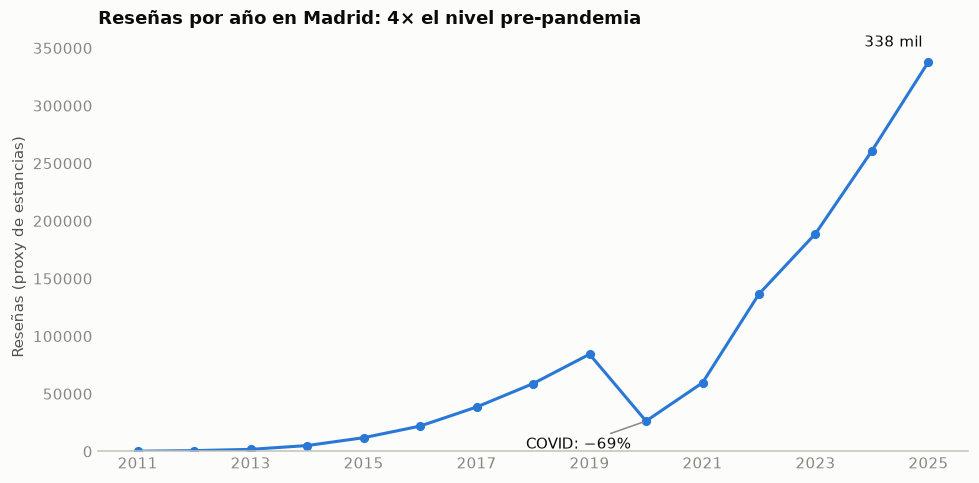

In [14]:
por_año = reviews.set_index('date').resample('YS').size()
por_año = por_año[(por_año.index.year >= 2011) & (por_año.index.year <= 2025)]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(por_año.index.year, por_año.values, color=BLUE, lw=2, marker='o', ms=5)
ax.annotate('COVID: −69%', (2020, por_año[por_año.index.year == 2020].iloc[0]),
            textcoords='offset points', xytext=(-10, -18), ha='right',
            fontsize=9.5, color=INK,
            arrowprops=dict(arrowstyle='-', color=MUTED, lw=1))
ax.annotate(f'{por_año.iloc[-1]/1000:.0f} mil', (2025, por_año.iloc[-1]),
            textcoords='offset points', xytext=(-4, 10), ha='right', fontsize=9.5, color=INK)
ax.set_title('Reseñas por año en Madrid: 4× el nivel pre-pandemia')
ax.set_ylabel('Reseñas (proxy de estancias)')
ax.set_ylim(0, None)
ax.set_xticks(range(2011, 2026, 2))
estilo(ax)
plt.tight_layout()
plt.show()

**Hallazgo:** la serie cuenta sola la historia del sector: crecimiento sostenido hasta
84 mil reseñas en 2019, desplome del **−69% en 2020**, y una recuperación explosiva hasta
**338 mil en 2025 — 4× el pico pre-pandemia**. El turismo urbano de Madrid no se recuperó:
se disparó.

**Para el dashboard:** serie temporal principal, con selector de barrio para comparar
recuperaciones.

## 8. Estacionalidad: octubre manda y agosto se hunde

Como la demanda se multiplicó por 4 en el periodo, promediar reseñas brutas por mes
sesgaría el perfil hacia los años recientes. En su lugar calculamos, para cada año
completo (2015–2025), **qué % de sus reseñas cae en cada mes**, y promediamos esos
porcentajes: un perfil estacional limpio de tendencia.

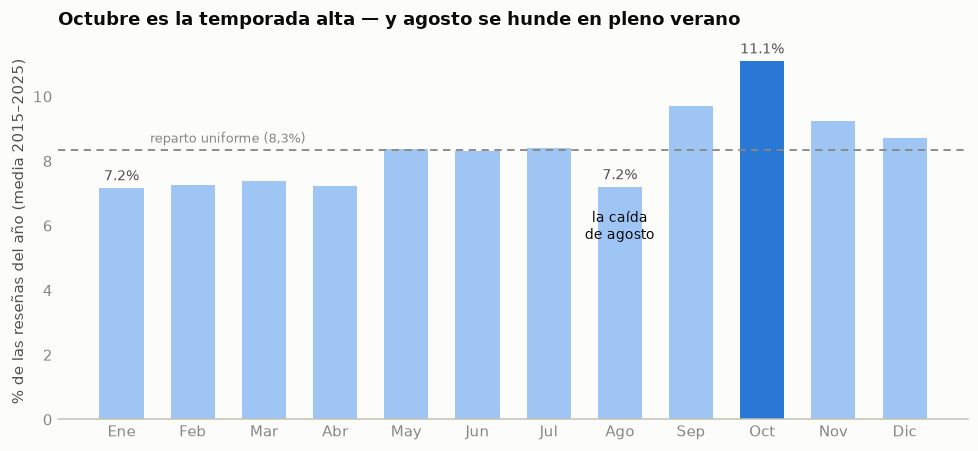

In [15]:
rv = reviews[(reviews.date >= '2015-01-01') & (reviews.date < '2026-01-01')]
mensual = rv.set_index('date').resample('MS').size().to_frame('n')
mensual['pct_año'] = mensual.n / mensual.n.groupby(mensual.index.year).transform('sum') * 100
perfil = mensual.pct_año.groupby(mensual.index.month).mean()
meses = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']

fig, ax = plt.subplots(figsize=(9, 4.2))
colores = [BLUE if m == 10 else BLUE_L for m in perfil.index]
bars = ax.bar(meses, perfil.values, color=colores, width=0.62)
destacar = (perfil.max(), perfil.min(), perfil[8])
ax.bar_label(bars, fmt=lambda v: f'{v:.1f}%' if v in destacar else '',
             padding=3, fontsize=9, color=INK2)
ax.axhline(100 / 12, color=MUTED, lw=1.2, ls=(0, (4, 3)))
ax.annotate('reparto uniforme (8,3%)', (0.4, 100 / 12), textcoords='offset points',
            xytext=(0, 5), fontsize=8.5, color=MUTED)
ax.annotate('la caída\nde agosto', (7, perfil[8]), textcoords='offset points',
            xytext=(0, -34), ha='center', fontsize=9, color=INK)
ax.set_title('Octubre es la temporada alta — y agosto se hunde en pleno verano')
ax.set_ylabel('% de las reseñas del año (media 2015–2025)')
estilo(ax)
plt.tight_layout()
plt.show()

**Hallazgo:** **octubre** es el mes fuerte de Madrid (11,1% de las estancias del año),
seguido del hombro otoñal (sep–nov) y del primaveral (may–jul). El invierno (ene–feb) es
la temporada baja y **agosto se hunde por debajo de julio y septiembre** en plena
temporada veraniega española: Madrid es un destino urbano — congresos, cultura, city
breaks — al que el calor de agosto le resta demanda, no se la suma.

**Para el dashboard:** gráfico de estacionalidad con filtro por barrio (¿los barrios
turísticos vs de negocios tienen perfiles distintos?).

## 9. El calendario futuro confirma el patrón

El calendario (jun 2026 → jun 2027) nos da la vista *forward-looking*: % de noches ya no
disponibles por fecha. **Cautela:** "no disponible" mezcla reservado y bloqueado por el
host, así que es techo de ocupación, no ocupación real; aun así, la *forma* de la curva es
informativa. Recortamos los últimos días del rango, donde quedan pocos anuncios con
calendario y el dato es ruido.

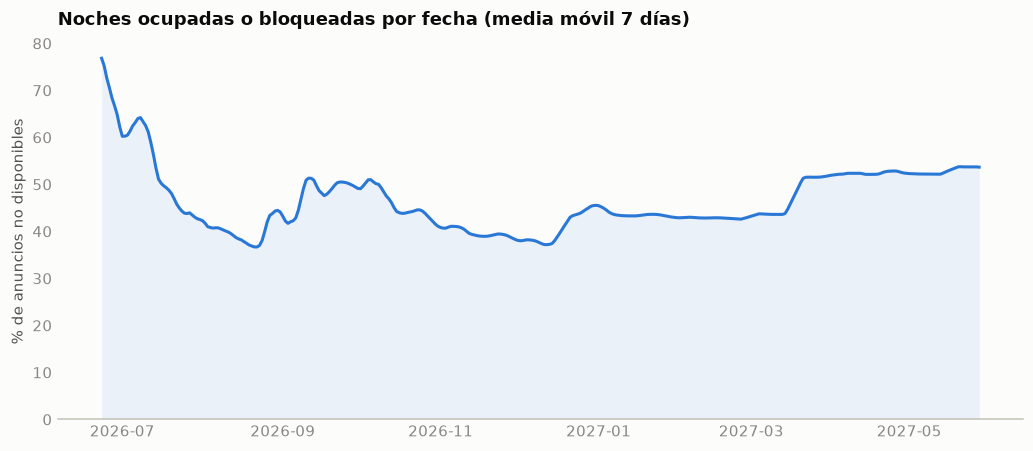

Por día de semana (%): {'L': 46.2, 'M': 46.0, 'X': 46.4, 'J': 47.5, 'V': 48.9, 'S': 49.2, 'D': 47.3}


In [16]:
ocupacion = 1 - cal.groupby('date')['available'].mean()
ocupacion = ocupacion[ocupacion.index <= '2027-05-31']
suave = ocupacion.rolling(7, center=True).mean()

fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.plot(suave.index, suave.values * 100, color=BLUE, lw=2)
ax.fill_between(suave.index, suave.values * 100, color=BLUE, alpha=0.08, lw=0)
ax.set_title('Noches ocupadas o bloqueadas por fecha (media móvil 7 días)')
ax.set_ylabel('% de anuncios no disponibles')
ax.set_ylim(0, 80)
estilo(ax)
plt.tight_layout()
plt.show()

dow = (1 - cal.groupby(cal.date.dt.dayofweek)['available'].mean()) * 100
print('Por día de semana (%):', {dia: round(v, 1) for dia, v in
      zip(['L', 'M', 'X', 'J', 'V', 'S', 'D'], dow)})

**Hallazgo:** hay que leer la curva con su sesgo: las fechas cercanas siempre parecen más
llenas porque acumulan más reservas ya hechas (efecto *lead time*). Por eso las señales
valiosas son las que van **contra** esa pendiente: la caída de **agosto de 2026 por debajo
de septiembre** (más lejano pero más lleno) y la subida de la **primavera de 2027 por
encima del invierno previo** replican exactamente la estacionalidad histórica de la
sección 8 con una fuente independiente. El efecto fin de semana existe pero es leve
(sábado ~50,6% vs lunes ~47,2%): la demanda entre semana (trabajo, congresos) sostiene la
ocupación.

**Para el dashboard:** curva de disponibilidad futura como vista "de presente/futuro"
junto a la histórica de reseñas.

## 10. Licencias: dos de cada tres anuncios declaran registro

Madrid exige licencia turística; el campo `license` recoge el número de registro declarado
(o su exención: hostales, alquiler de temporada…). Lo tratamos como "declara registro
sí/no" — no podemos verificar su validez.

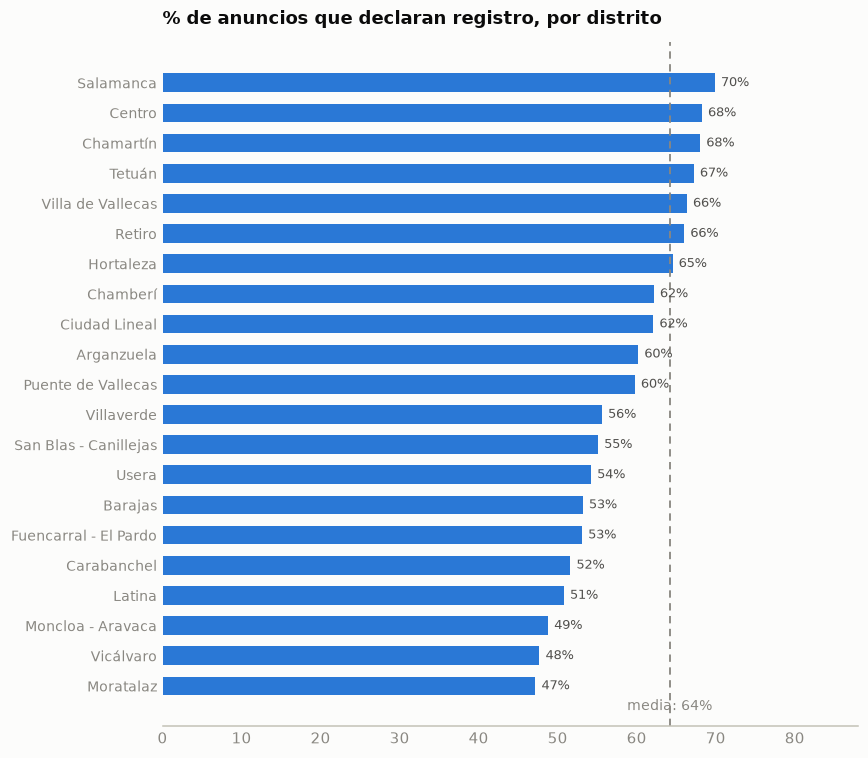

In [17]:
lic = listings.assign(con_licencia=listings.license.notna())
por_dist_lic = (lic.groupby('neighbourhood_group', observed=True)['con_licencia']
                .mean().sort_values() * 100)
total = lic.con_licencia.mean() * 100

fig, ax = plt.subplots(figsize=(8, 7))
bars = ax.barh(por_dist_lic.index.astype(str), por_dist_lic.values, color=BLUE, height=0.62)
ax.bar_label(bars, fmt='%.0f%%', padding=4, fontsize=8.5, color=INK2)
ax.axvline(total, color=MUTED, lw=1.2, ls=(0, (4, 3)))
ax.annotate(f'media: {total:.0f}%', (total, -0.8), fontsize=9, color=MUTED, ha='center')
ax.set_title('% de anuncios que declaran registro, por distrito')
ax.set_xlim(0, 88)
ax.tick_params(axis='y', labelsize=9)
estilo(ax, eje='x')
plt.tight_layout()
plt.show()

**Hallazgo:** el 64% de los anuncios declara registro, pero con un gradiente
centro-periferia **inverso al que cabría esperar**: los distritos con más presión
turística (Salamanca 70%, Centro 68%) declaran *más* que la periferia (Moratalaz 47%,
Vicálvaro 48%) — probablemente porque en el centro operan los hosts profesionales, que
sí tramitan registro. Tema de máxima actualidad regulatoria en Madrid.

**Para el dashboard:** capa "% licencias" en el mapa coroplético + cruce con tipo de host.

## 11. Conclusiones: qué va al dashboard

| # | Hallazgo | Visual propuesto |
|---|----------|------------------|
| 1 | El precio lo marca la capacidad, no la calidad (r=0,60 vs 0,09) | Barras de correlación + scatter interactivo |
| 2 | Piso entero 143 € / habitación 64 € / compartida 25 € | Filtro global por tipo + KPI |
| 3 | Salamanca dobla a la periferia; el premium se agota a 3 km del centro | **Mapa coroplético** (geojson) con selector de métrica |
| 4 | Los pisos caros ganan hasta en "calidad-precio" (4,59 vs 4,51) | Tarjeta "dato sorpresa" |
| 5 | 32% de la oferta en manos de hosts con 21+ anuncios; peor rating (4,52 vs 4,74) | Segmentador tipo de host + comparativa |
| 6 | Superhost: mismo precio, 2,6× más demanda | KPI + toggle en filtros |
| 7 | Demanda 4× sobre el nivel pre-COVID (338 mil reseñas en 2025) | Serie temporal principal |
| 8 | Octubre es la temporada alta (11% del año); agosto se hunde en pleno verano | Gráfico de estacionalidad con filtro de barrio |
| 9 | El calendario futuro replica el patrón estacional | Curva de disponibilidad futura |
| 10 | 64% declara licencia; el centro cumple más que la periferia | Capa del mapa + cruce con tipo de host |

**Estructura sugerida del dashboard (Streamlit):** una fila de KPIs (anuncios activos,
precio mediano, % licencias, reseñas último año), el mapa coroplético como pieza central
con selector de métrica, la serie temporal de demanda, y una fila de filtros globales
(distrito, tipo de alojamiento, tipo de host, sólo Superhosts). `reviews_full.parquet`
(223 MB) **no** se carga en el dashboard: pre-agregaremos lo necesario a un parquet pequeño.